In [3]:
import os, re, json, hashlib, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

# ===================== الإعدادات =====================
CSV_PATH     = "authentic_ai_enhanced_generated_data.csv"
OUT_DIR      = "processed_data"
SEED         = 42          # seed ثابت لكل شيء عشوائي
NEAR_DUP_THR = 0.85        # عتبة TF-IDF cosine لاعتبار نصين شبه متطابقين (نُزلت من 0.95 بعد أن كشف فحص التسريب زوجًا بتشابه 0.97)

# نسب التقسيم 70/15/15 (نقسم لـ 20 fold: 3 للـ test + 3 للـ val + 14 للـ train)
N_FOLDS, TEST_FOLDS, VAL_FOLDS = 20, 3, 3
CV_FOLDS_IN_TRAIN = 5      # folds إضافية داخل الـ Train فقط لاختيار/ضبط الموديل لاحقًا

label_names = {0: "Authentic", 1: "AI-Generated", 2: "AI-Enhanced"}
label2id    = {v: k for k, v in label_names.items()}
id2label    = dict(label_names)
# =====================================================

df = pd.read_csv(CSV_PATH)
df["label_name"] = df["Label"].map(label_names)
df.head()

,Name,Text,Label,label_name
0,118_resume_job4_authentic_0.pdf,Data driven analytical and highly creative Senior Project Manager with 7 years of experience in leading digital transformation projects excels at planning managing and executing multichannel marke...,0,Authentic
1,136_resume_job3_authentic_0.pdf,name: phone number: email linkedin.comingthampi http:github.comgthampi Summary Proven software engineer and researcher with a Masters degree in Computer Science and a rich portfolio of projects in...,0,Authentic
2,78_resume_job4_authentic_0.pdf,name address phone number email Security Clearance PROFESSIONAL SUMMARY: Dedicated and enthusiastic Certified Project Management Professional with over 7 years extensive experience in managing ove...,0,Authentic
3,121_resume_job4_authentic_0.pdf,name address phone number email Relocating to address Information Technology professional with over a decade of experience in project management and customer service. I have a deep understanding o...,0,Authentic
4,79_resume_job4_authentic_0.pdf,name Project Manager email phone number EMPLOYMENT HISTORY: Project Manager III company date to Present address Managing time budget and scope for multiple projects with a maximum value of 25 mill...,0,Authentic


In [5]:

print(f"عدد الصفوف (Samples) الكلي : {df.shape[0]}")
print(f"عدد الأعمدة               : {df.shape[1]}")
print("\nأسماء الأعمدة:", list(df.columns))
print("\n--- Info ---")
df.info()

عدد الصفوف (Samples) الكلي : 421
عدد الأعمدة               : 4

أسماء الأعمدة: ['Name', 'Text', 'Label', 'label_name']

--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421 entries, 0 to 420
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Name        421 non-null    object
 1   Text        421 non-null    object
 2   Label       421 non-null    int64 
 3   label_name  421 non-null    object
dtypes: int64(1), object(3)
memory usage: 13.3+ KB


In [7]:
# استخراج المعلومات من اسم الملف
# مثال: 118_resume_job4_authentic_0_enhanced.pdf -> rid=118 , job=job4 , source=authentic_0_enhanced , ext=pdf
meta = df["Name"].str.extract(r"^(?P<rid>\d+)_resume_(?P<job>job\d+)_(?P<source>.+?)\.(?P<ext>pdf|docx)$")
assert meta.notna().all().all(), "في أسماء ملفات لا تطابق النمط!"
df = pd.concat([df, meta], axis=1)
df["pair_key"] = df["rid"] + "_" + df["job"]     # يربط Authentic مع نسخته AI-Enhanced

pd.crosstab(df["source"], df["Label"], margins=True)

Label,0,1,2,All
source,,,,
ChatGPT_1,0,30,0,30
Gemini_1,0,63,0,63
Meta_1,0,48,0,48
authentic_0,141,0,0,141
authentic_0_enhanced,0,0,139,139
All,141,141,139,421


,Class,Samples,Percentage %
Label,,,
0,Authentic,141,33.49
1,AI-Generated,141,33.49
2,AI-Enhanced,139,33.02



Imbalance Ratio (max/min) = 1.01
✅ الداتا Balanced تقريبًا (الفرق بين الكلاسات بسيط جدًا)


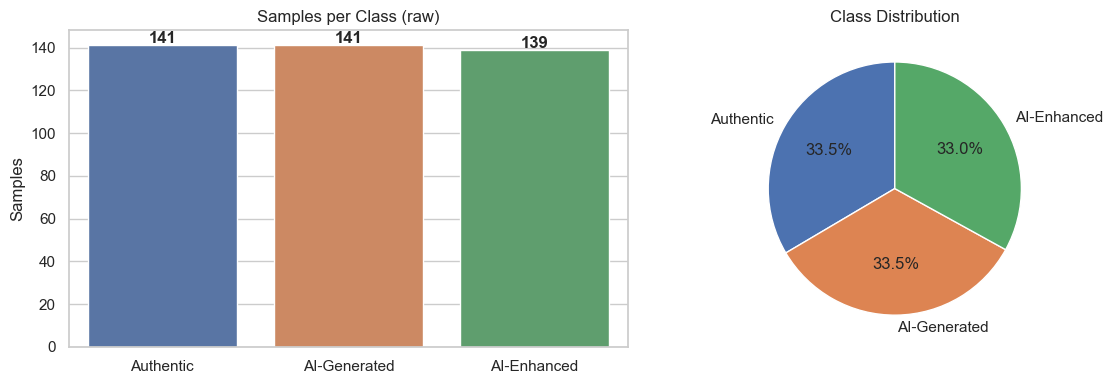

In [9]:
counts = df["Label"].value_counts().sort_index()
summary = pd.DataFrame({
    "Class": [label_names[i] for i in counts.index],
    "Samples": counts.values,
    "Percentage %": (counts.values / len(df) * 100).round(2),
})
summary.index = counts.index.rename("Label")
display(summary)

# نسبة عدم التوازن: أكبر كلاس / أصغر كلاس (1.0 = متوازن تمامًا)
imbalance_ratio = counts.max() / counts.min()
print(f"\nImbalance Ratio (max/min) = {imbalance_ratio:.2f}")
if imbalance_ratio < 1.5:
    print("✅ الداتا Balanced تقريبًا (الفرق بين الكلاسات بسيط جدًا)")
elif imbalance_ratio < 3:
    print("⚠️ الداتا فيها Imbalance خفيف/متوسط")
else:
    print("❌ الداتا Imbalanced بشكل واضح")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=summary["Class"], y=summary["Samples"], hue=summary["Class"], ax=ax[0], legend=False)
for i, v in enumerate(summary["Samples"]):
    ax[0].text(i, v + 1, str(v), ha="center", fontweight="bold")
ax[0].set_title("Samples per Class (raw)"); ax[0].set_xlabel("")
ax[1].pie(summary["Samples"], labels=summary["Class"], autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class Distribution")
plt.tight_layout(); plt.show()

In [11]:
missing = pd.DataFrame({
    "Missing (NaN)": df[["Name", "Text", "Label"]].isna().sum(),
})
# نفحص كمان النصوص الفارغة أو اللي فيها مسافات بس
missing.loc["Text", "Empty/Whitespace-only"] = (df["Text"].fillna("").str.strip() == "").sum()
missing["Empty/Whitespace-only"] = missing["Empty/Whitespace-only"].fillna(0).astype(int)
display(missing)

if missing.values.sum() == 0:
    print("no Missing Values")
else:
    print("في قيم ناقصة")

print("\nأقصر 5 نصوص (للتأكد أنه ما في نص شبه فارغ):")
display(df.assign(n_chars=df["Text"].fillna("").str.len()).nsmallest(5, "n_chars")[["Name", "label_name", "n_chars"]])

,Missing (NaN),Empty/Whitespace-only
Name,0,0
Text,0,0
Label,0,0


no Missing Values

أقصر 5 نصوص (للتأكد أنه ما في نص شبه فارغ):


,Name,label_name,n_chars
118,77_resume_job5_authentic_0.pdf,Authentic,618
43,138_resume_job3_authentic_0.pdf,Authentic,890
277,43_resume_job2_ChatGPT_1.pdf,AI-Generated,937
131,28_resume_job1_authentic_0.pdf,Authentic,941
150,47_resume_job2_ChatGPT_1.pdf,AI-Generated,946


In [13]:
print("صفوف مكررة بالكامل (كل الأعمدة)   :", df[["Name", "Text", "Label"]].duplicated().sum())
print("أسماء ملفات مكررة (Name)           :", df["Name"].duplicated().sum())
print("نصوص مكررة (Text)                  :", df["Text"].duplicated().sum(), "(الصفوف الزايدة بعد أول نسخة)")

# مفتاح للمقارنة فقط (لا يُستخدم كـ feature ولا يغيّر النص): lower + توحيد المسافات
df["dup_key"] = df["Text"].fillna("").str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
print("نصوص مكررة بعد توحيد المسافات/الحالة :", df["dup_key"].duplicated().sum())

dup_mask = df["dup_key"].duplicated(keep=False)
print("عدد الصفوف المشاركة بنصوص مكررة    :", dup_mask.sum())
print("عدد النصوص الفريدة المكررة         :", df[dup_mask]["dup_key"].nunique())

print("\nالنصوص المكررة موزعة على الكلاسات:")
display(df[dup_mask].groupby(["Label", "source"]).size().rename("Rows").to_frame())

# هل نفس النص مأخوذ بـ Label مختلف؟ (تعارض)
conflict = df[dup_mask].groupby("dup_key")["Label"].nunique()
print("نصوص مكررة بـ Labels مختلفة (تعارض):", (conflict > 1).sum())

صفوف مكررة بالكامل (كل الأعمدة)   : 0
أسماء ملفات مكررة (Name)           : 0
نصوص مكررة (Text)                  : 18 (الصفوف الزايدة بعد أول نسخة)
نصوص مكررة بعد توحيد المسافات/الحالة : 20
عدد الصفوف المشاركة بنصوص مكررة    : 29
عدد النصوص الفريدة المكررة         : 9

النصوص المكررة موزعة على الكلاسات:


Rows
Label source           
0     authentic_0     4
1     ChatGPT_1      10
      Meta_1         15

نصوص مكررة بـ Labels مختلفة (تعارض): 0


In [15]:
N_EXAMPLES = 3      # عدد الأمثلة لكل كلاس
MAX_CHARS  = 600    # كم حرف نعرض من كل سيرة

for label in sorted(df["Label"].unique()):
    print("=" * 100)
    print(f"Label {label}  →  {label_names[label]}")
    print("=" * 100)
    sample = df[df["Label"] == label].sample(N_EXAMPLES, random_state=SEED)
    for i, (_, row) in enumerate(sample.iterrows(), 1):
        print(f"\n[{i}] File: {row['Name']}")
        print(row["Text"][:MAX_CHARS].replace("\n", " ") + " ...")
    print()

Label 0  →  Authentic

[1] File: 45_resume_job3_authentic_0.pdf
name Phone: phone number Email: email Summary Driven professional offering a progressive 9year career in information technology seeking a leadership role to expand knowledge and enhance skill sets. Proven track record of consistently achieving organizational goals by directing IT projects from inception to execution providing robust solutions that incorporate a wide range of applications and emerging technologies. Software Knowledge Windows Operating Systems 11 10 8.1 7 XP Windows Server OS date date date date date date Microsoft HyperV Virtualization VMware Virtualization ESX ESXi vSphere 6 W ...

[2] File: 32_resume_job5_authentic_0.pdf
name address address email phone number sales within multiple industries. Proven track record in exceeding sales goals growing business and expanding territories. Accomplished in overseeing daytoday business operations and fostering relationships with customers and clients for sustained b

job,job1,job2,job3,job4,job5
label_name,,,,,
AI-Enhanced,15,22,30,42,30
AI-Generated,42,23,20,19,37
Authentic,16,22,30,43,30


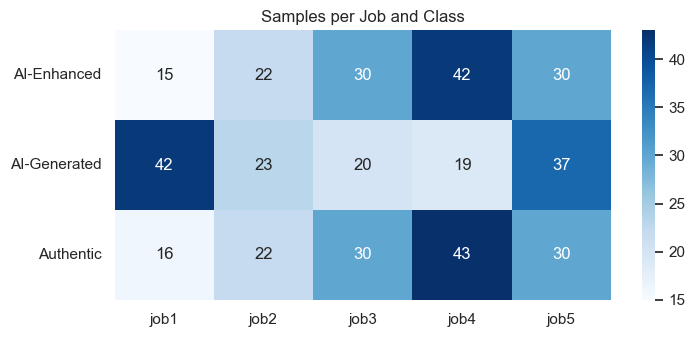

In [17]:
job_ct = pd.crosstab(df["label_name"], df["job"])
display(job_ct)

plt.figure(figsize=(8, 3.5))
sns.heatmap(job_ct, annot=True, fmt="d", cmap="Blues")
plt.title("Samples per Job and Class"); plt.ylabel(""); plt.xlabel("")
plt.show()

label_name     AI-Enhanced  AI-Generated  Authentic
n_words count        139.0         141.0      141.0
        mean         763.6         298.9      597.6
        std          309.8         105.4      306.7
        min          216.0         114.0       92.0
        25%          538.5         208.0      389.0
        50%          723.0         243.0      566.0
        75%          941.0         398.0      758.0
        max         1810.0         532.0     1636.0
n_chars count        139.0         141.0      141.0
        mean        5759.9        2347.1     4367.9
        std         2396.4         813.4     2303.9
        min         1867.0         937.0      618.0
        25%         4187.0        1640.0     2687.0
        50%         5363.0        1852.0     4049.0
        75%         7211.5        3129.0     5678.0
        max        13912.0        4311.0    12728.0

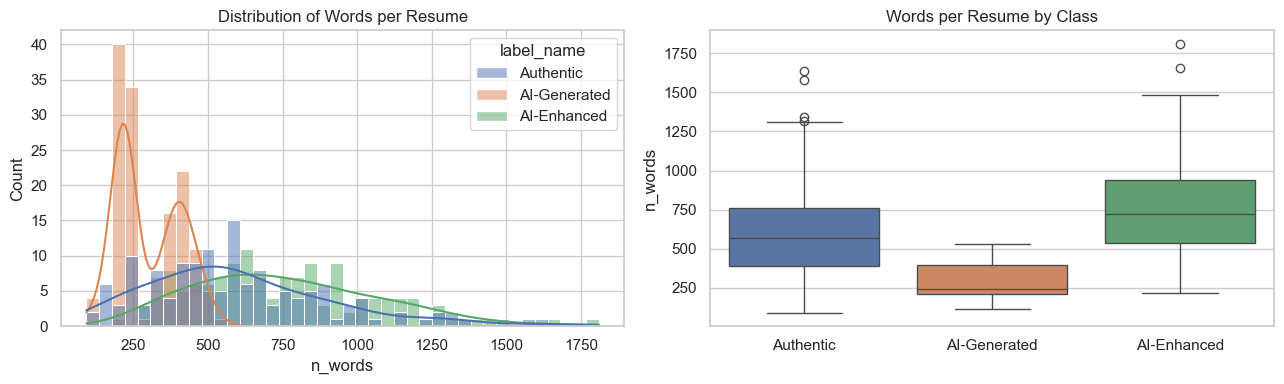

In [19]:
df["n_words"] = df["Text"].str.split().str.len()
df["n_chars"] = df["Text"].str.len()

display(df.groupby("label_name")[["n_words", "n_chars"]].describe().round(1).T)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="n_words", hue="label_name", bins=40, kde=True, ax=ax[0])
ax[0].set_title("Distribution of Words per Resume")
sns.boxplot(data=df, x="label_name", y="n_words", hue="label_name", ax=ax[1], legend=False)
ax[1].set_title("Words per Resume by Class"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

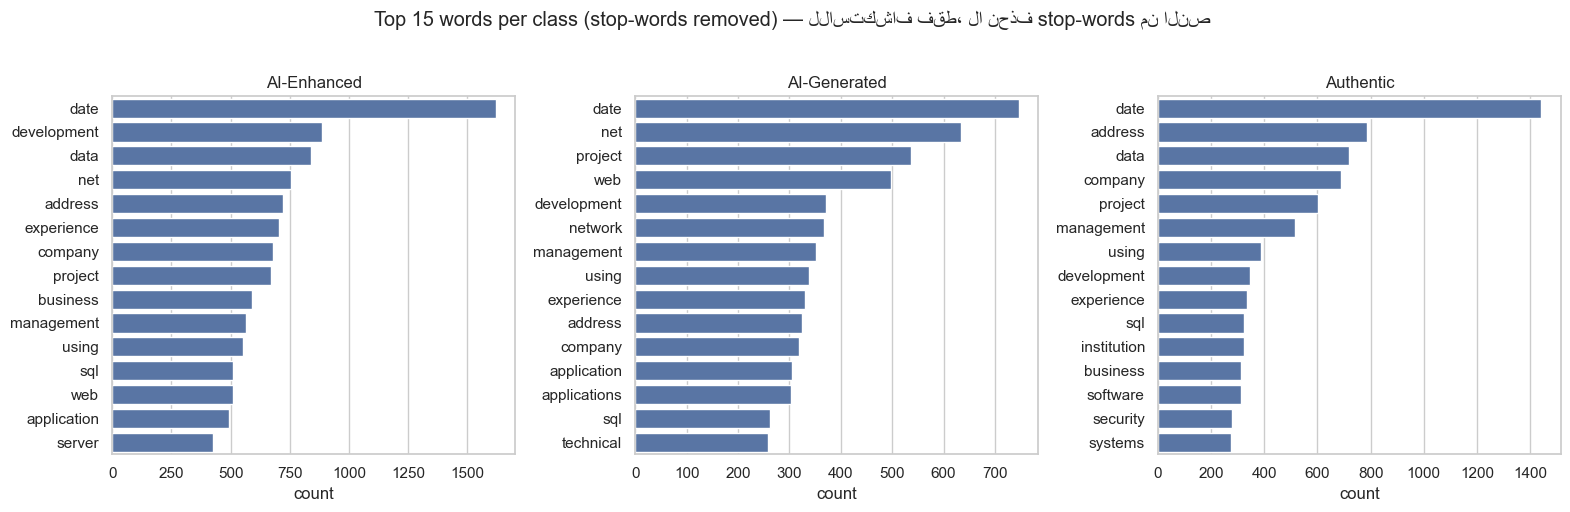

In [21]:
def top_words(texts, n=15):
    words = []
    for t in texts:
        words += [w for w in re.findall(r"[a-zA-Z]{3,}", t.lower()) if w not in ENGLISH_STOP_WORDS]
    return Counter(words).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (label, g) in zip(axes, df.groupby("label_name")):
    tw = pd.DataFrame(top_words(g["Text"]), columns=["word", "count"])
    sns.barplot(data=tw, y="word", x="count", ax=ax, color=sns.color_palette()[0])
    ax.set_title(label); ax.set_ylabel("")
plt.suptitle("Top 15 words per class (stop-words removed) — للاستكشاف فقط، لا نحذف stop-words من النص", y=1.02)
plt.tight_layout(); plt.show()

In [23]:
# --- Near-duplicates بالـ TF-IDF (للكشف فقط، لا يُستخدم للتدريب) ---
tfidf_dup = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
SIM = cosine_similarity(tfidf_dup.fit_transform(df["Text"].fillna("")))
np.fill_diagonal(SIM, 0)
ii, jj = np.where(np.triu(SIM, 1) >= NEAR_DUP_THR)
print(f"أزواج Near-duplicate (cosine >= {NEAR_DUP_THR}): {len(ii)}")

# --- Union-Find ---
parent = list(range(len(df)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

# (1) Authentic <-> AI-Enhanced
for _, g in df[df["Label"].isin([0, 2])].groupby("pair_key"):
    idx = list(g.index)
    for j in idx[1:]:
        union(idx[0], j)
# (2) نصوص متطابقة
for _, g in df.groupby("dup_key"):
    idx = list(g.index)
    for j in idx[1:]:
        union(idx[0], j)
# (3) شبه متطابقة
for a, b in zip(ii, jj):
    union(a, b)

df["group_id"] = [find(i) for i in range(len(df))]
sizes = df["group_id"].value_counts()
print(f"عدد المجموعات: {sizes.shape[0]} | أكبر مجموعة: {sizes.max()} سيرة")
print("\nعدد الفئات داخل كل مجموعة (2 = مجموعة فيها Authentic + Enhanced):")
display(df.groupby("group_id")["Label"].nunique().value_counts().rename("عدد المجموعات").to_frame())

أزواج Near-duplicate (cosine >= 0.85): 359
عدد المجموعات: 226 | أكبر مجموعة: 19 سيرة

عدد الفئات داخل كل مجموعة (2 = مجموعة فيها Authentic + Enhanced):


,عدد المجموعات
Label,
2,131
1,95


In [25]:
n0 = len(df)

# (1) حذف الفارغ/الناقص
bad = df["Text"].isna() | (df["Text"].fillna("").str.strip() == "") | df["Label"].isna()
removed_empty = df[bad].copy()
df_work = df[~bad].copy()

# (2) حذف التكرار الحرفي: نبقي أول نسخة ونحفظ المحذوف للتدقيق
dup_removed_mask = df_work["dup_key"].duplicated(keep="first")
removed_dups = df_work[dup_removed_mask].copy()
df_clean = df_work[~dup_removed_mask].reset_index(drop=True)

print(f"قبل: {n0} | محذوف (فارغ/ناقص): {len(removed_empty)} | محذوف (تكرار حرفي): {len(removed_dups)} | بعد: {len(df_clean)}")
display(pd.DataFrame({
    "Before": df["label_name"].value_counts(),
    "After":  df_clean["label_name"].value_counts(),
}).loc[list(label_names.values())].assign(Removed=lambda t: t.Before - t.After))

os.makedirs(OUT_DIR, exist_ok=True)
removed_dups[["Name", "label_name", "source", "job"]].to_csv(f"{OUT_DIR}/removed_duplicates.csv", index=False)

قبل: 421 | محذوف (فارغ/ناقص): 0 | محذوف (تكرار حرفي): 20 | بعد: 401


,Before,After,Removed
label_name,,,
Authentic,141,139,2
AI-Generated,141,123,18
AI-Enhanced,139,139,0


In [27]:
def minimal_clean(t: str) -> str:
    # فقط: حذف محرف NULL + مسافات/أسطر في أول وآخر النص.
    # لا lowercase / لا حذف ترقيم / لا حذف أرقام / لا stop-words / لا stemming / لا دمج أسطر.
    return t.replace("\x00", "").strip()

df_clean["text"]    = df_clean["Text"].apply(minimal_clean)
df_clean["n_words"] = df_clean["text"].str.split().str.len()
df_clean["n_chars"] = df_clean["text"].str.len()

# فحص الحفاظ على الأسلوب: نقارن مؤشرات أسلوبية قبل/بعد
def style_stats(s):
    return pd.DataFrame({
        "punctuation":  s.str.count(r"[^\w\s]"),
        "uppercase":    s.str.count(r"[A-Z]"),
        "digits":       s.str.count(r"\d"),
        "newlines":     s.str.count(r"\n"),
        "sentences":    s.str.count(r"[.!?]+"),
    }).sum()

cmp = pd.DataFrame({"Before (raw)": style_stats(df_clean["Text"]), "After (clean)": style_stats(df_clean["text"])})
cmp["Changed?"] = cmp["Before (raw)"] != cmp["After (clean)"]
display(cmp)
assert not cmp["Changed?"].any(), "التنظيف غيّر مؤشرات أسلوبية!"
print("✅ الترقيم والأحرف الكبيرة والأرقام والأسطر والجمل كما هي بلا أي تغيير")

,Before (raw),After (clean),Changed?
punctuation,20377,20377,False
uppercase,109635,109635,False
digits,7411,7411,False
newlines,1558,1558,False
sentences,11509,11509,False


✅ الترقيم والأحرف الكبيرة والأرقام والأسطر والجمل كما هي بلا أي تغيير


In [29]:
df_clean["label"] = df_clean["label_name"].map(label2id).astype(int)
assert (df_clean["label"] == df_clean["Label"]).all(), "تعارض بين الـ Label الأصلي والمُشتق"
assert set(df_clean["label"].unique()) == set(label_names), "فئة ناقصة!"

print("label2id :", label2id)
print("id2label :", id2label)
display(df_clean["label_name"].value_counts().loc[list(label_names.values())].rename("Samples").to_frame())

label2id : {'Authentic': 0, 'AI-Generated': 1, 'AI-Enhanced': 2}
id2label : {0: 'Authentic', 1: 'AI-Generated', 2: 'AI-Enhanced'}


,Samples
label_name,
Authentic,139
AI-Generated,123
AI-Enhanced,139


In [31]:
y      = df_clean["label"].values
groups = df_clean["group_id"].values

order = ["train", "val", "test"]
TARGET_SHARE = {"train": 0.70, "val": 0.15, "test": 0.15}
overall_cls  = df_clean["label_name"].value_counts(normalize=True)

def make_split(seed):
    sk = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    f20 = np.full(len(df_clean), -1)
    for k, (_, idx) in enumerate(sk.split(df_clean, y, groups)):
        f20[idx] = k
    sp = np.where(f20 < TEST_FOLDS, "test", np.where(f20 < TEST_FOLDS + VAL_FOLDS, "val", "train"))
    return f20, sp

def split_score(sp):
    # كلما قلّ كان أفضل: انحراف حجم الأجزاء عن 70/15/15 + انحراف نسب الفئات عن نسبها في كل الداتا
    s = 0.0
    for part in order:
        m = sp == part
        s += abs(m.mean() - TARGET_SHARE[part])
        s += (df_clean.loc[m, "label_name"].value_counts(normalize=True).reindex(overall_cls.index).fillna(0) - overall_cls).abs().sum()
    return s

# نختار أفضل seed من مدى ثابت (0..199) — لا علاقة للاختيار بأي موديل أو نتائج تقييم، والقيمة الناتجة ثابتة ومسجّلة
SPLIT_SEED = min(range(200), key=lambda sd: split_score(make_split(sd)[1]))
fold20, split_arr = make_split(SPLIT_SEED)
assert (fold20 >= 0).all()
df_clean["split"] = split_arr
print(f"SPLIT_SEED المختار = {SPLIT_SEED} | score = {split_score(split_arr):.3f}")

dist = pd.crosstab(df_clean["split"], df_clean["label_name"])[list(label_names.values())].loc[order]
dist["Total"] = dist.sum(axis=1)
dist["Share %"] = (dist["Total"] / dist["Total"].sum() * 100).round(1)
display(dist)

print("نسبة كل فئة داخل كل جزء (%):")
display((pd.crosstab(df_clean["split"], df_clean["label_name"], normalize="index")[list(label_names.values())].loc[order] * 100).round(1))
print("نسبة الفئات في الداتا كاملة (%):")
display((df_clean["label_name"].value_counts(normalize=True).loc[list(label_names.values())] * 100).round(1).to_frame("All").T)

SPLIT_SEED المختار = 12 | score = 0.169


label_name,Authentic,AI-Generated,AI-Enhanced,Total,Share %
split,,,,,
train,105,94,104,303,75.6
val,21,18,22,61,15.2
test,13,11,13,37,9.2


نسبة كل فئة داخل كل جزء (%):


label_name,Authentic,AI-Generated,AI-Enhanced
split,,,
train,34.7,31.0,34.3
val,34.4,29.5,36.1
test,35.1,29.7,35.1


نسبة الفئات في الداتا كاملة (%):


label_name,Authentic,AI-Generated,AI-Enhanced
All,34.7,30.7,34.7


In [33]:
parts = {s: df_clean[df_clean["split"] == s] for s in order}

# 1) لا تقاطع في group_id
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (set(parts[a].group_id) & set(parts[b].group_id)), f"تسريب مجموعات بين {a} و {b}"
# 2) لا تقاطع في النصوص
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (set(parts[a].dup_key) & set(parts[b].dup_key)), f"نص مكرر بين {a} و {b}"
# 3) كل زوج Authentic/Enhanced في جزء واحد
pair_split = df_clean[df_clean["Label"].isin([0, 2])].groupby("pair_key")["split"].nunique()
assert (pair_split == 1).all(), "زوج Authentic/Enhanced موزّع على أكثر من جزء!"
# 4) لا تقاطع في أسماء الملفات
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (set(parts[a].Name) & set(parts[b].Name))

print("✅ لا تقاطع في: group_id / النصوص / أزواج Authentic↔Enhanced / أسماء الملفات")

full_pairs = (df_clean[df_clean["Label"].isin([0, 2])].groupby(["split", "pair_key"]).size().loc[lambda s: s == 2]
              .groupby("split").size())
print("أزواج Authentic+Enhanced الكاملة داخل كل جزء:", full_pairs.to_dict())

# أعلى تشابه بين أي سيرة في Val/Test وأي سيرة في Train (TF-IDF مضبوط على Train فقط)
tf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(parts["train"]["text"])
Xtr = tf.transform(parts["train"]["text"])
for s in ["val", "test"]:
    mx = cosine_similarity(tf.transform(parts[s]["text"]), Xtr).max()
    print(f"أعلى cosine بين {s} و train: {mx:.3f}  (العتبة {NEAR_DUP_THR})")
    assert mx < NEAR_DUP_THR, f"سيرة في {s} شبه مطابقة لسيرة في train!"

✅ لا تقاطع في: group_id / النصوص / أزواج Authentic↔Enhanced / أسماء الملفات
أزواج Authentic+Enhanced الكاملة داخل كل جزء: {'test': 13, 'train': 103, 'val': 21}
أعلى cosine بين val و train: 0.723  (العتبة 0.85)
أعلى cosine بين test و train: 0.659  (العتبة 0.85)


In [35]:
df_clean["cv_fold"] = -1
tr = df_clean[df_clean["split"] == "train"]
cv = StratifiedGroupKFold(n_splits=CV_FOLDS_IN_TRAIN, shuffle=True, random_state=SEED)
for k, (_, va_idx) in enumerate(cv.split(tr, tr["label"], tr["group_id"])):
    df_clean.loc[tr.index[va_idx], "cv_fold"] = k

tr = df_clean[df_clean["split"] == "train"]
display(pd.crosstab(tr["cv_fold"], tr["label_name"])[list(label_names.values())])

label_name,Authentic,AI-Generated,AI-Enhanced
cv_fold,,,
0,17,20,17
1,16,13,14
2,21,24,21
3,24,24,25
4,27,13,27


In [37]:
FEATURE_COL, TARGET_COL = "text", "label"
TRACKING_COLS = ["Name", "label_name", "job", "source", "ext", "pair_key", "group_id", "n_words", "n_chars"]
base_cols = [FEATURE_COL, TARGET_COL] + TRACKING_COLS

df_clean[base_cols + ["split", "cv_fold"]].to_csv(f"{OUT_DIR}/resumes_clean_with_split.csv", index=False)
df_clean[df_clean.split == "train"][base_cols + ["cv_fold"]].reset_index(drop=True).to_csv(f"{OUT_DIR}/train.csv", index=False)
df_clean[df_clean.split == "val"][base_cols].reset_index(drop=True).to_csv(f"{OUT_DIR}/val.csv", index=False)
df_clean[df_clean.split == "test"][base_cols].reset_index(drop=True).to_csv(f"{OUT_DIR}/test.csv", index=False)

def sha256(path):
    return hashlib.sha256(open(path, "rb").read()).hexdigest()

report = {
    "source_file": CSV_PATH, "seed": SEED, "split_seed": int(SPLIT_SEED),
    "rows_raw": int(n0), "removed_empty": int(len(removed_empty)),
    "removed_exact_duplicates": int(len(removed_dups)), "rows_final": int(len(df_clean)),
    "near_duplicate_threshold": NEAR_DUP_THR, "n_groups": int(df_clean["group_id"].nunique()),
    "split_method": f"StratifiedGroupKFold(n_splits={N_FOLDS}) -> test={TEST_FOLDS}, val={VAL_FOLDS}, train={N_FOLDS - TEST_FOLDS - VAL_FOLDS} folds",
    "split_counts": {s: int(len(parts[s])) for s in order},
    "split_class_counts": {s: {k: int(v) for k, v in parts[s]["label_name"].value_counts().items()} for s in order},
    "label2id": label2id,
    "feature_column": FEATURE_COL, "target_column": TARGET_COL, "tracking_columns_not_for_training": TRACKING_COLS,
    "test_sha256": sha256(f"{OUT_DIR}/test.csv"),
}
with open(f"{OUT_DIR}/split_report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
with open(f"{OUT_DIR}/label_map.json", "w") as f:
    json.dump({"label2id": label2id, "id2label": {str(k): v for k, v in id2label.items()}}, f, indent=2)

print("الملفات المحفوظة في:", OUT_DIR)
for fn in sorted(os.listdir(OUT_DIR)):
    print(f"  {fn:32s} {os.path.getsize(os.path.join(OUT_DIR, fn)) / 1024:8.1f} KB")
print("\nTest SHA-256:", report["test_sha256"][:16], "...")

الملفات المحفوظة في: processed_data
  label_map.json                        0.2 KB
  removed_duplicates.csv                1.1 KB
  resumes_clean_with_split.csv       1704.8 KB
  split_report.json                     1.1 KB
  test.csv                            149.9 KB
  train.csv                          1303.5 KB
  val.csv                             249.0 KB

Test SHA-256: 318513acdff34716 ...
